# 05 · Model Comparison: EfficientNet-B0 vs ResNet50 vs DenseNet121
This notebook loads the test-set metrics saved by notebooks 02-04
(`results/<model>_metrics.json`), compares the three backbones side by side and selects the best
model for deployment, with the reasoning spelled out.

## 0. Environment setup
This first cell detects whether the notebook runs on **Google Colab**. On Colab it installs the
required packages and uses `/content/skin-cancer-detection` as the project folder (select
*Runtime → Change runtime type → GPU*). Locally it uses the project root (the parent of `notebooks/`).
All paths are built with `pathlib`, so the notebook runs unchanged on macOS, Linux and Windows.

In [1]:
import sys, subprocess, os, json, time, random, warnings
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-U", "kaggle", "opencv-python-headless",
                    "seaborn", "scikit-learn", "pandas", "matplotlib"], check=True)
    ROOT = Path("/content/skin-cancer-detection")
else:
    ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

DATA_DIR = ROOT / "data"
RAW_DIR = DATA_DIR / "raw"                # original HAM10000 download
PROCESSED_DIR = DATA_DIR / "processed"    # cached preprocessed 224x224 images
SPLITS_DIR = DATA_DIR / "splits"          # train/val/test CSVs
MODELS_DIR = ROOT / "models"
RESULTS_DIR = ROOT / "results"
for d in (RAW_DIR, PROCESSED_DIR, SPLITS_DIR, MODELS_DIR, RESULTS_DIR):
    d.mkdir(parents=True, exist_ok=True)

warnings.filterwarnings("ignore", category=UserWarning)
print("Running on Colab:", IN_COLAB)
print("Project root   :", ROOT)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
sns.set_theme(style="whitegrid")
CLASS_NAMES = ["akiec", "bcc", "bkl", "df", "mel", "nv", "vasc"]

Running on Colab: False
Project root   : /Users/udaymallikarjun/Documents/sanya/skincancer/skin-cancer-detection


## 1. Load the saved metrics

In [2]:
MODELS = {"efficientnet_b0": "EfficientNet-B0", "resnet50": "ResNet50", "densenet121": "DenseNet121"}
metrics = {}
for key, label in MODELS.items():
    f = RESULTS_DIR / f"{key}_metrics.json"
    if f.exists():
        metrics[label] = json.loads(f.read_text())
    else:
        print(f"Missing {f.name} - run the {label} notebook first.")
assert metrics, "No metrics found"

rows = []
for label, m in metrics.items():
    o, b = m["overall"], m["binary"]
    rows.append({"model": label, "params_millions": m["params_millions"], "accuracy": o["accuracy"],
                 "balanced_accuracy": o["balanced_accuracy"], "macro_precision": o["macro_precision"],
                 "macro_recall_sensitivity": o["macro_recall_sensitivity"], "macro_specificity": o["macro_specificity"],
                 "macro_f1": o["macro_f1"], "weighted_f1": o["weighted_f1"], "macro_roc_auc": o["macro_roc_auc"],
                 "bin_accuracy": b["accuracy"], "bin_precision": b["precision"], "bin_sensitivity": b["sensitivity"],
                 "bin_specificity": b["specificity"], "bin_f1": b["f1"], "bin_roc_auc": b["roc_auc"],
                 "epochs_run": m["epochs_run"], "best_epoch": m["best_epoch"], "train_minutes": m["train_minutes"]})
comp = pd.DataFrame(rows)
comp.round(4).to_csv(RESULTS_DIR / "model_comparison.csv", index=False)
display(comp.set_index("model").T.round(4))

model,EfficientNet-B0,ResNet50,DenseNet121
params_millions,4.0200,23.5200,6.9600
accuracy,0.8196,0.8016,0.7929
balanced_accuracy,0.7228,0.6822,0.6559
macro_precision,0.7282,0.7042,0.6983
macro_recall_sensitivity,0.7228,0.6822,0.6559
macro_specificity,0.9587,0.9564,0.9511
macro_f1,0.7206,0.6879,0.6478
weighted_f1,0.8221,0.8079,0.7925
macro_roc_auc,0.9279,0.9447,0.9399
bin_accuracy,0.8762,0.8655,0.8695


## 2. Overall 7-class metrics

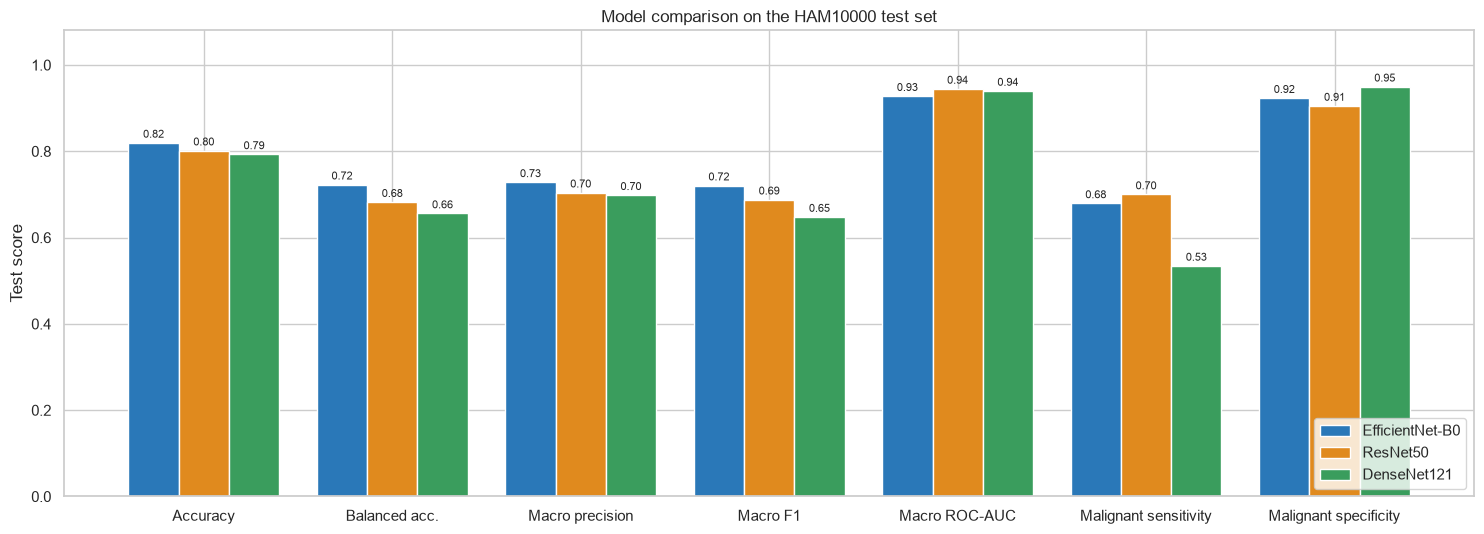

In [3]:
METRICS = [("accuracy", "Accuracy"), ("balanced_accuracy", "Balanced acc."), ("macro_precision", "Macro precision"),
           ("macro_f1", "Macro F1"), ("macro_roc_auc", "Macro ROC-AUC"), ("bin_sensitivity", "Malignant sensitivity"),
           ("bin_specificity", "Malignant specificity")]
palette = ["#2a78b8", "#e08a1e", "#3a9d5d"]
x = np.arange(len(METRICS)); w = 0.8 / len(comp)
fig, ax = plt.subplots(figsize=(15, 5.5))
for i, r in comp.iterrows():
    bars = ax.bar(x + (i - (len(comp) - 1) / 2) * w, [r[k] for k, _ in METRICS], w, label=r["model"], color=palette[i])
    ax.bar_label(bars, fmt="%.2f", fontsize=8, padding=2)
ax.set_xticks(x, [l for _, l in METRICS]); ax.set_ylim(0, 1.08); ax.set_ylabel("Test score")
ax.set_title("Model comparison on the HAM10000 test set"); ax.legend(loc="lower right")
plt.tight_layout(); plt.savefig(RESULTS_DIR / "model_comparison.png", dpi=150); plt.show()

## 3. Per-class comparison
F1 and sensitivity per class reveal where the models differ, especially on the rare and malignant classes.

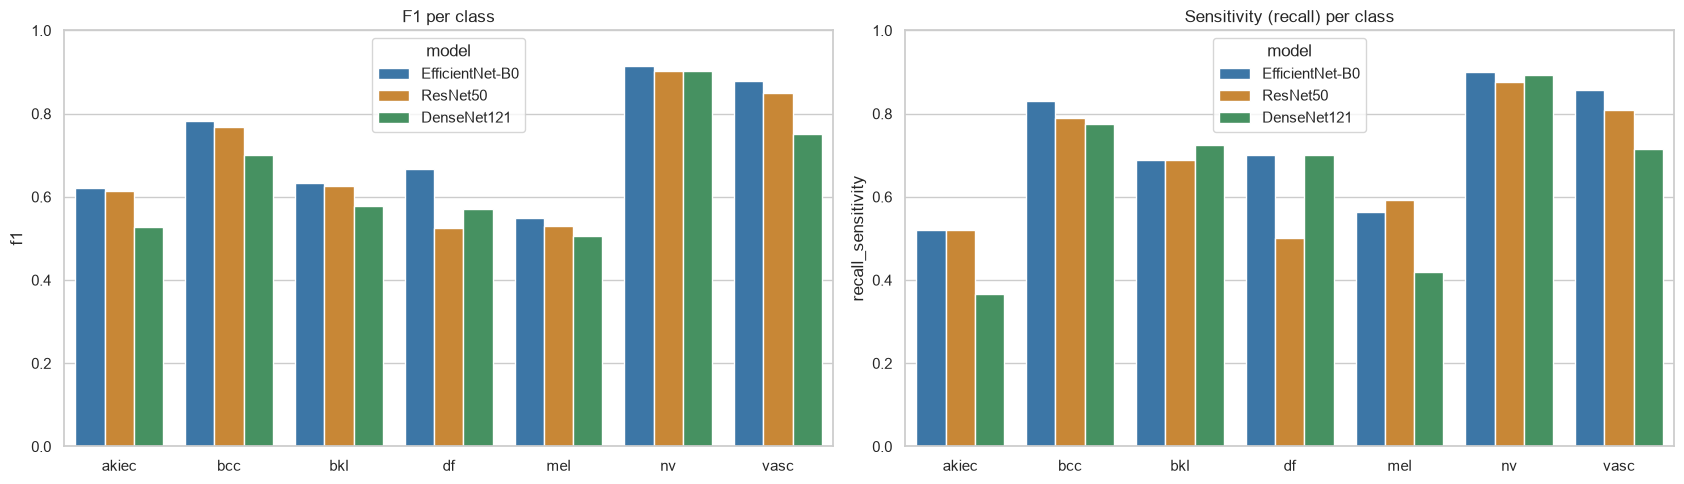

model,DenseNet121,EfficientNet-B0,ResNet50
ROC-AUC per class,,,
akiec,0.9867,0.8616,0.9741
bcc,0.9751,0.9697,0.9660
bkl,0.9243,0.9191,0.9227
df,0.8952,0.9733,0.9419
mel,0.8720,0.8791,0.8871
nv,0.9301,0.9377,0.9431
vasc,0.9956,0.9544,0.9777


In [4]:
pc = pd.concat([pd.DataFrame(m["per_class"]).assign(model=label) for label, m in metrics.items()])
fig, axes = plt.subplots(1, 2, figsize=(17, 5))
for ax, col, t in zip(axes, ["f1", "recall_sensitivity"], ["F1 per class", "Sensitivity (recall) per class"]):
    sns.barplot(pc, x="class", y=col, hue="model", order=CLASS_NAMES, palette=palette, ax=ax)
    ax.set_title(t); ax.set_ylim(0, 1); ax.set_xlabel("")
plt.tight_layout(); plt.savefig(RESULTS_DIR / "model_comparison_per_class.png", dpi=150); plt.show()
display(pc.pivot(index="class", columns="model", values="roc_auc").loc[CLASS_NAMES].round(4).rename_axis("ROC-AUC per class"))

## 4. Training dynamics and efficiency

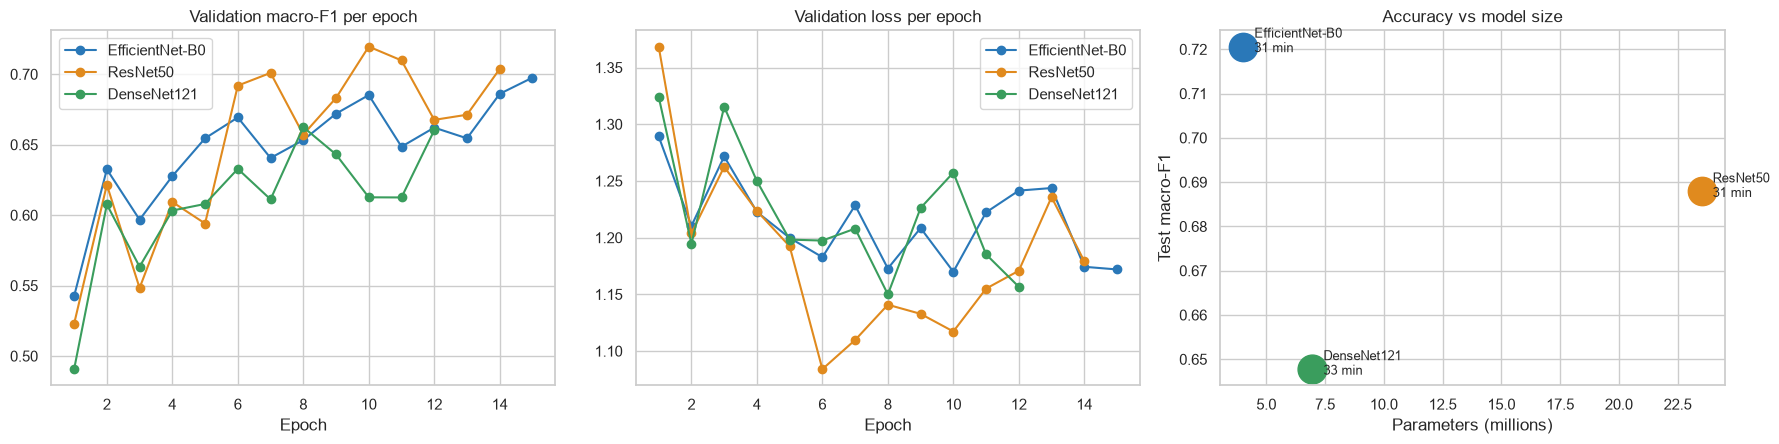

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.6))
for i, (key, label) in enumerate(MODELS.items()):
    f = RESULTS_DIR / key / "training_history.csv"
    if f.exists():
        h = pd.read_csv(f)
        axes[0].plot(h.epoch, h.val_f1, "o-", color=palette[i], label=label)
        axes[1].plot(h.epoch, h.val_loss, "o-", color=palette[i], label=label)
axes[0].set_title("Validation macro-F1 per epoch"); axes[1].set_title("Validation loss per epoch")
for ax in axes[:2]: ax.set_xlabel("Epoch"); ax.legend()
for i, r in comp.iterrows():
    axes[2].scatter(r.params_millions, r.macro_f1, s=40 + 12 * r.train_minutes, color=palette[i], label=r["model"])
    axes[2].annotate(f"{r['model']}\n{r.train_minutes:.0f} min", (r.params_millions, r.macro_f1),
                     textcoords="offset points", xytext=(8, -4), fontsize=9)
axes[2].set_xlabel("Parameters (millions)"); axes[2].set_ylabel("Test macro-F1"); axes[2].set_title("Accuracy vs model size")
plt.tight_layout(); plt.savefig(RESULTS_DIR / "model_comparison_training.png", dpi=150); plt.show()

## 5. Selecting the best model
Selection criteria, in order of importance for a skin-cancer decision-support tool:

1. **Macro F1** on the test set: balances precision and recall over *all seven* classes, so it is not
   dominated by the majority class (nevi).
2. **Malignant sensitivity** and **benign-vs-malignant ROC-AUC**: missing a cancer is the most
   costly error.
3. **Macro ROC-AUC**: the quality of the probability ranking, independent of the decision threshold.
4. **Model size / speed**: important for deployment in the web app.

A weighted score combines criteria 1-3 (0.4 · macro-F1 + 0.3 · malignant sensitivity + 0.3 · binary AUC); size breaks near-ties (< 0.005).

In [6]:
comp["selection_score"] = 0.4 * comp.macro_f1 + 0.3 * comp.bin_sensitivity + 0.3 * comp.bin_roc_auc
ranked = comp.sort_values(["selection_score"], ascending=False).reset_index(drop=True)
top = ranked.iloc[0]
near = ranked[ranked.selection_score >= top.selection_score - 0.005]
best = near.sort_values("params_millions").iloc[0]
display(ranked[["model", "macro_f1", "bin_sensitivity", "bin_roc_auc", "macro_roc_auc", "accuracy",
                "params_millions", "train_minutes", "selection_score"]].round(4))

others = ranked[ranked.model != best.model]
lines = [f"Best model: {best.model}", ""]
lines.append(f"- Selection score {best.selection_score:.4f} (rank {int(ranked.index[ranked.model == best.model][0]) + 1} of {len(ranked)}).")
lines.append(f"- Macro F1 {best.macro_f1:.4f} vs " + ", ".join(f"{r.model} {r.macro_f1:.4f}" for r in others.itertuples()) + ".")
lines.append(f"- Malignant sensitivity {best.bin_sensitivity:.4f} / specificity {best.bin_specificity:.4f}; "
             f"benign-vs-malignant AUC {best.bin_roc_auc:.4f}.")
lines.append(f"- Macro ROC-AUC {best.macro_roc_auc:.4f}; accuracy {best.accuracy:.4f}.")
lines.append(f"- Size {best.params_millions:.1f} M parameters, trained in {best.train_minutes:.0f} min.")
if best.model != top.model:
    lines.append(f"- {top.model} scored marginally higher ({top.selection_score:.4f}) but the gap is < 0.005, "
                 f"so the smaller {best.model} is preferred for deployment.")
print("\n".join(lines))

key = {v: k for k, v in MODELS.items()}[best.model]
(RESULTS_DIR / "best_model.json").write_text(json.dumps(
    {"best_model": key, "display_name": best.model, "selection_score": float(best.selection_score),
     "reasoning": lines[2:]}, indent=2))
print(f"\nSaved results/best_model.json and results/model_comparison.csv")

,model,macro_f1,bin_sensitivity,bin_roc_auc,macro_roc_auc,accuracy,params_millions,train_minutes,selection_score
0,EfficientNet-B0,0.7206,0.6793,0.8854,0.9279,0.8196,4.02,31.41,0.7577
1,ResNet50,0.6879,0.7000,0.9020,0.9447,0.8016,23.52,31.46,0.7558
2,DenseNet121,0.6478,0.5345,0.8945,0.9399,0.7929,6.96,32.58,0.6878


Best model: EfficientNet-B0

- Selection score 0.7577 (rank 1 of 3).
- Macro F1 0.7206 vs ResNet50 0.6879, DenseNet121 0.6478.
- Malignant sensitivity 0.6793 / specificity 0.9233; benign-vs-malignant AUC 0.8854.
- Macro ROC-AUC 0.9279; accuracy 0.8196.
- Size 4.0 M parameters, trained in 31 min.

Saved results/best_model.json and results/model_comparison.csv


## Conclusion
The table and charts above compare the three transfer-learning backbones on identical, leakage-free
data splits, preprocessing, augmentation and training settings, so the differences come from the
architectures themselves. The selected model (printed above, also stored in `results/best_model.json`)
is used by default by the Streamlit application and the prediction CLI.

**Disclaimer:** these models are research / educational tools and are not a medical diagnosis.